# KNN (k-nearest neighbours)

**How it works:** to classify a flow, find the `k` training flows that are closest to it (in the 45-dimensional scaled feature space) and let them vote. Closer neighbours count for more (`weights="distance"`).

**Feasibility:** works, but it has no real training step. It stores the whole training set (about 140,000 rows) and compares each new flow against all of them, so prediction is slow and scales badly. It is a good offline comparison model, and a poor choice for live detection. It also has no class-weight option, so rare classes can be outvoted.

Run after the preprocessing notebook. Everything is evaluated on the validation set.

## 1. Imports

In [1]:
import json
import time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    ConfusionMatrixDisplay, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

## 2. Config

`MAX_TRAIN_ROWS` lets you train on a stratified subset if prediction is too slow on your machine (for example `60000`). Leave it as `None` to use everything.

In [2]:
PROCESSED_DIR = "processed"
MODEL_DIR = "models"
SEED = 42

K_GRID = (3, 5, 11, 21)     # candidate values of k
TUNE_ROWS = 5000            # validation rows used to pick k (keeps tuning fast)
MAX_TRAIN_ROWS = None

## 3. Load the processed data

In [3]:
proc = Path(PROCESSED_DIR)
data = np.load(proc / "unsw_nb15_processed.npz")
meta = json.loads((proc / "meta.json").read_text())

X_train, X_val = data["X_train"].astype("float32"), data["X_val"].astype("float32")
yb_train, yb_val = data["y_bin_train"].astype(int), data["y_bin_val"].astype(int)
ym_train, ym_val = data["y_multi_train"].astype(int), data["y_multi_val"].astype(int)
feature_names = meta["feature_names"]
class_names = meta["class_names"]
n_features, n_classes = X_train.shape[1], len(class_names)

cw_bin = {int(k): v for k, v in meta["class_weight_binary"].items()}
cw_multi = {int(k): v for k, v in meta["class_weight_multi"].items()}

print("X_train:", X_train.shape, "  X_val:", X_val.shape)
print("classes:", class_names)

X_train: (140272, 39)   X_val: (35069, 39)
classes: ['Normal', 'DoS', 'Reconnaissance', 'Fuzzers', 'Exploits', 'Generic', 'Other']


## 4. Helpers (same evaluation as every other notebook)

In [4]:
def ms_per_1000(predict_fn, X, n=5000):
    """Prediction time in milliseconds per 1,000 flows (a model that is too slow cannot run live)."""
    Xs = X[:n]
    t0 = time.perf_counter()
    predict_fn(Xs)
    return round(1e6 * (time.perf_counter() - t0) / len(Xs), 1)


def report_binary(y_true, pred, title, score=None, ms=None):
    print(classification_report(y_true, pred, target_names=["Normal", "Attack"], digits=4))
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1)
    if score is not None:
        print(f"ROC-AUC:              {roc_auc_score(y_true, score):.4f}")
    print(f"False positive rate:  {fpr:.4f}  ({fp} normal flows flagged as attacks)")
    print(f"False negative rate:  {fn / max(fn + tp, 1):.4f}  ({fn} attacks missed)")
    fig, ax = plt.subplots(figsize=(4.5, 4))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, display_labels=["Normal", "Attack"], cmap="Blues", ax=ax, values_format="d")
    ax.set_title(f"{title}: validation confusion matrix")
    plt.tight_layout()
    plt.show()
    return {"model": title,
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred),
            "f1": f1_score(y_true, pred),
            "false_pos_rate": fpr,
            "ms_per_1000_flows": ms}


def report_multiclass(y_true, pred, title, ms=None):
    labels = list(range(n_classes))
    print(classification_report(y_true, pred, labels=labels, target_names=class_names,
                                digits=4, zero_division=0))
    print("macro F1:    %.4f" % f1_score(y_true, pred, average="macro"))
    print("weighted F1: %.4f" % f1_score(y_true, pred, average="weighted"))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        cmap="Blues", ax=axes[0], values_format="d", xticks_rotation=45)
    axes[0].set_title("Counts")
    ConfusionMatrixDisplay.from_predictions(
        y_true, pred, labels=labels, display_labels=class_names,
        normalize="true", cmap="Blues", ax=axes[1], values_format=".2f", xticks_rotation=45)
    axes[1].set_title("Row-normalised (share of each true class)")
    plt.suptitle(f"{title}: validation confusion matrices")
    plt.tight_layout()
    plt.show()
    flagged = np.asarray(pred) != 0          # class 0 is Normal
    rows = []
    for i, name in enumerate(class_names):
        m = np.asarray(y_true) == i
        rows.append({"true class": name, "flows": int(m.sum()),
                     "flagged as attack (%)": round(100 * flagged[m].mean(), 2),
                     "correct type (%)": round(100 * (np.asarray(pred)[m] == i).mean(), 2)})
    display(pd.DataFrame(rows))
    return {"model": title + " (macro)",
            "precision": precision_score(y_true, pred, average="macro", zero_division=0),
            "recall": recall_score(y_true, pred, average="macro", zero_division=0),
            "f1": f1_score(y_true, pred, average="macro"),
            "false_pos_rate": np.nan,
            "ms_per_1000_flows": ms}

## 5. Optional subsample and choosing k

In [5]:
if MAX_TRAIN_ROWS and MAX_TRAIN_ROWS < len(X_train):
    idx, _ = train_test_split(np.arange(len(X_train)), train_size=MAX_TRAIN_ROWS,
                              stratify=ym_train, random_state=SEED)
    X_fit, yb_fit, ym_fit = X_train[idx], yb_train[idx], ym_train[idx]
else:
    X_fit, yb_fit, ym_fit = X_train, yb_train, ym_train
print("training rows used:", len(X_fit))

rng = np.random.default_rng(SEED)
tune_idx = rng.choice(len(X_val), size=min(TUNE_ROWS, len(X_val)), replace=False)


def tune_k(y_fit, y_val_full, average):
    rows = []
    for k in K_GRID:
        knn = KNeighborsClassifier(n_neighbors=k, weights="distance", n_jobs=-1).fit(X_fit, y_fit)
        pred = knn.predict(X_val[tune_idx])
        rows.append({"k": k, "f1": f1_score(y_val_full[tune_idx], pred, average=average)})
    df = pd.DataFrame(rows)
    display(df.round(4))
    return int(df.sort_values("f1", ascending=False).iloc[0]["k"])


best_k_bin = tune_k(yb_fit, yb_val, "binary")
best_k_multi = tune_k(ym_fit, ym_val, "macro")
print("best k  binary:", best_k_bin, "  multiclass:", best_k_multi)

training rows used: 140272


,k,f1
0,3,0.9591
1,5,0.9616
2,11,0.9651
3,21,0.9645


,k,f1
0,3,0.5857
1,5,0.5916
2,11,0.5965
3,21,0.5903


best k  binary: 11   multiclass: 11


## 6. Binary KNN (normal vs attack)

predicted 35,069 flows in 5.3s
              precision    recall  f1-score   support

      Normal     0.9199    0.9356    0.9277     11200
      Attack     0.9695    0.9617    0.9656     23869

    accuracy                         0.9534     35069
   macro avg     0.9447    0.9487    0.9467     35069
weighted avg     0.9537    0.9534    0.9535     35069

ROC-AUC:              0.9882
False positive rate:  0.0644  (721 normal flows flagged as attacks)
False negative rate:  0.0383  (913 attacks missed)


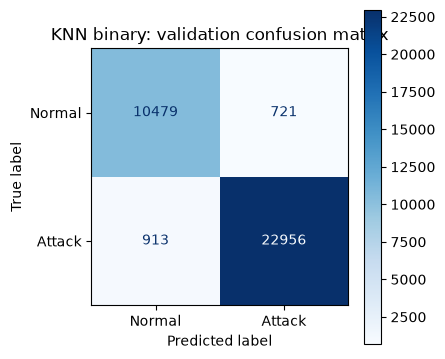

In [6]:
knn_bin = KNeighborsClassifier(n_neighbors=best_k_bin, weights="distance", n_jobs=-1).fit(X_fit, yb_fit)
t0 = time.time()
proba_bin = knn_bin.predict_proba(X_val)[:, 1]
print(f"predicted {len(X_val):,} flows in {time.time() - t0:.1f}s")
pred_bin = (proba_bin >= 0.5).astype(int)
row_bin = report_binary(yb_val, pred_bin, "KNN binary", score=proba_bin,
                        ms=ms_per_1000(knn_bin.predict, X_val, n=2000))

## 7. Multiclass KNN

                precision    recall  f1-score   support

        Normal     0.9109    0.9406    0.9255     11200
           DoS     0.0397    0.0453    0.0423      2453
Reconnaissance     0.7253    0.7408    0.7330      2099
       Fuzzers     0.7439    0.6582    0.6985      3637
      Exploits     0.5406    0.5253    0.5328      6678
       Generic     0.9914    0.9820    0.9867      8000
         Other     0.2409    0.2236    0.2319      1002

      accuracy                         0.7466     35069
     macro avg     0.5990    0.5880    0.5930     35069
  weighted avg     0.7503    0.7466    0.7480     35069

macro F1:    0.5930
weighted F1: 0.7480


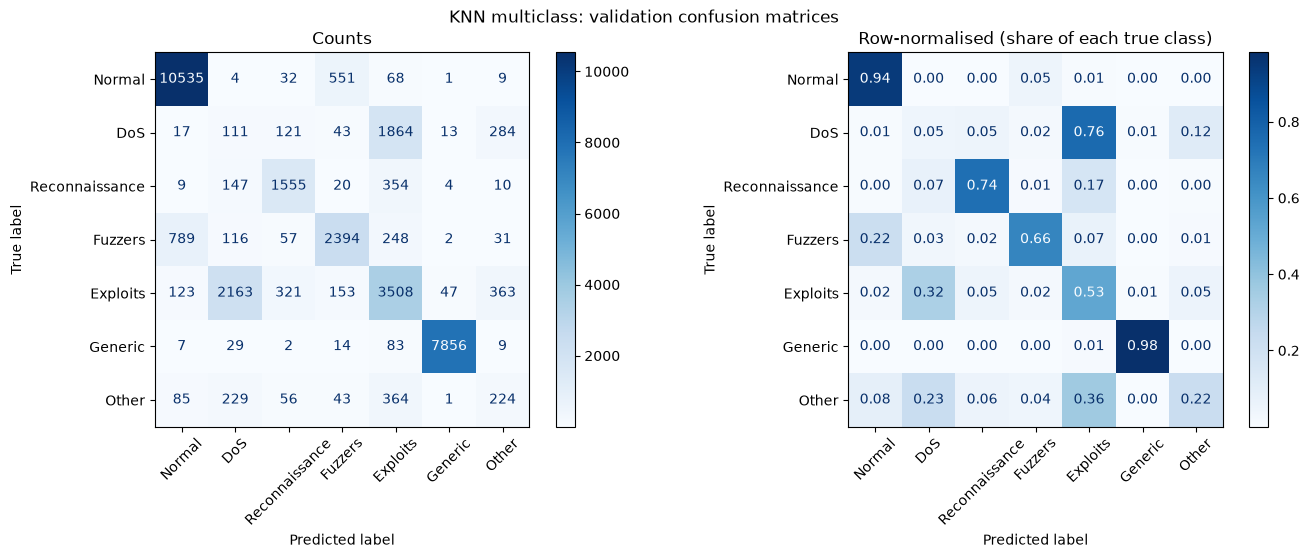

,true class,flows,flagged as attack (%),correct type (%)
0,Normal,11200,5.94,94.06
1,DoS,2453,99.31,4.53
2,Reconnaissance,2099,99.57,74.08
3,Fuzzers,3637,78.31,65.82
4,Exploits,6678,98.16,52.53
5,Generic,8000,99.91,98.20
6,Other,1002,91.52,22.36


In [7]:
knn_multi = KNeighborsClassifier(n_neighbors=best_k_multi, weights="distance", n_jobs=-1).fit(X_fit, ym_fit)
pred_multi = knn_multi.predict(X_val)
row_multi = report_multiclass(ym_val, pred_multi, "KNN multiclass",
                              ms=ms_per_1000(knn_multi.predict, X_val, n=2000))

## 8. Save and compare

The saved KNN file contains the whole training set, so it is large. The `ms_per_1000_flows` column in the comparison table shows how much slower KNN is than the tree models and neural networks.

In [8]:
mdir = Path(MODEL_DIR)
mdir.mkdir(exist_ok=True)
joblib.dump(knn_bin, mdir / "knn_binary.joblib", compress=3)
joblib.dump(knn_multi, mdir / "knn_multiclass.joblib", compress=3)
pd.DataFrame([row_bin, row_multi]).to_csv(mdir / "knn_validation_summary.csv", index=False)
for f in sorted(mdir.glob("knn_*")):
    print(f"{f.name:30s} {f.stat().st_size / 1e6:8.1f} MB")

knn_binary.joblib                   2.8 MB
knn_multiclass.joblib               2.9 MB
knn_validation_summary.csv          0.0 MB


In [9]:
# compare with every other model whose notebook has been run
frames = [pd.read_csv(f) for f in sorted(Path(MODEL_DIR).glob("*_validation_summary.csv"))]
pd.concat(frames, ignore_index=True).round(4)

,model,precision,recall,f1,false_pos_rate,ms_per_1000_flows
0,Autoencoder binary,0.9666,0.6791,0.7977,0.0500,NaN
1,ANN binary,0.9763,0.9288,0.9520,0.0479,10.0
2,ANN multiclass (macro),0.7079,0.7254,0.6912,NaN,10.0
3,DNN binary,0.9791,0.9345,0.9563,0.0424,11.3
4,DNN multiclass (macro),0.7072,0.7316,0.6950,NaN,10.2
5,K-Means anomaly binary,0.9496,0.4424,0.6036,0.0501,0.6
6,K-Means cluster-majority binary,0.9129,0.9512,0.9317,0.1934,0.1
7,K-Means cluster-majority multiclass (macro),0.4769,0.5241,0.4953,NaN,0.1
8,KNN binary,0.9695,0.9617,0.9656,0.0644,163.0
9,KNN multiclass (macro),0.5990,0.5880,0.5930,NaN,156.4
